# 02 — Kümeleme: Şarkılar doğal gruplara ayrılıyor mu?

Bu notebook'ta iki soruya cevap arıyoruz:

1. Şarkıları yalnızca **ses özelliklerine** bakarak gruplara ayırırsak, ortaya anlamlı "çalma listeleri" çıkar mı?
2. Spotify'ın **tür etiketleri** bu ses gruplarıyla örtüşüyor mu?

Yöntem: **K-Means** kümeleme, görselleştirme için **PCA** ve **t-SNE**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path.cwd().parent))
from src.veri import SES_OZELLIKLERI, temizle, tekil_sarkilar, veri_yukle

FIGURLER = Path.cwd().parent / "figures"
RASTGELE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
df = temizle(veri_yukle())        # tür düzeyi (aynı şarkı birden fazla türde olabilir)
sarkilar = tekil_sarkilar(df)     # her şarkı bir kez
print(f"{len(sarkilar):,} tekil şarkı, {len(SES_OZELLIKLERI)} ses özelliği")

89,578 tekil şarkı, 9 ses özelliği


## 1. Ölçekleme

K-Means mesafeye dayalı çalışır. `tempo` 50–200 arasında, `danceability` ise 0–1 arasında değişiyor. Ölçeklemezsek tempo tek başına kümeleri belirler. Bu yüzden her özelliği ortalaması 0, standart sapması 1 olacak şekilde ölçekliyoruz.

In [3]:
olcekleyici = StandardScaler()
X = olcekleyici.fit_transform(sarkilar[SES_OZELLIKLERI])

## 2. Kaç küme?

İki ölçüte bakıyoruz:
- **Inertia (dirsek yöntemi):** Küme içi toplam uzaklık. Küme sayısı arttıkça hep düşer. Düşüşün yavaşladığı "dirsek" noktası aranır.
- **Silhouette skoru:** Şarkıların kendi kümelerine, komşu kümelere göre ne kadar yakın olduğu. −1 ile 1 arasında, yüksek olan daha iyi. Hesabı ağır olduğu için 10.000 şarkılık bir örneklemle hesaplıyoruz.

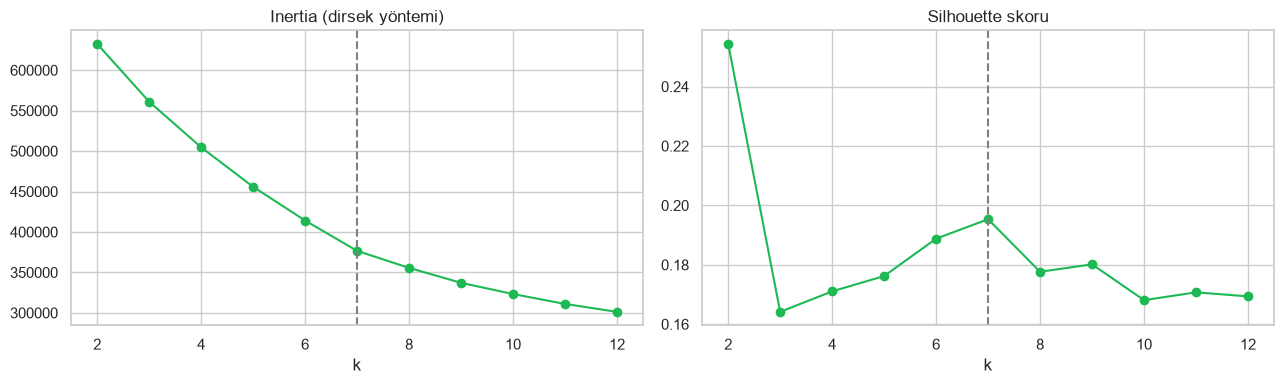

,inertia,silhouette
k,,
2,632568.640,0.254
3,561035.980,0.164
4,504694.801,0.171
5,455847.002,0.176
6,414120.827,0.189
7,376636.825,0.195
8,355556.974,0.178
9,337119.695,0.180
10,323254.993,0.168


In [4]:
rng = np.random.default_rng(RASTGELE)
orneklem = rng.choice(len(X), 10_000, replace=False)

sonuclar = []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=RASTGELE).fit(X)
    sonuclar.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X[orneklem], km.labels_[orneklem]),
    })
sonuclar = pd.DataFrame(sonuclar).set_index("k")

fig, (e1, e2) = plt.subplots(1, 2, figsize=(13, 4))
sonuclar["inertia"].plot(marker="o", ax=e1, color="#1DB954", title="Inertia (dirsek yöntemi)")
sonuclar["silhouette"].plot(marker="o", ax=e2, color="#1DB954", title="Silhouette skoru")
for e in (e1, e2):
    e.axvline(7, ls="--", color="gray")
fig.tight_layout()
fig.savefig(FIGURLER / "02_kume_sayisi.png", dpi=120)
plt.show()
sonuclar.round(3)

**Yorum:**
- Silhouette skorları **düşük** (0.16–0.25). Bu bir hata değil, bir bulgu: Müzik birbirinden keskin çizgilerle ayrılan gruplardan oluşmuyor. Şarkılar sürekli bir yelpazeye yayılıyor ve kümeler arasındaki sınırlar bulanık.
- En yüksek skor k=2'de. Ama 2 küme yalnızca kaba bir ayrım veriyor (aşağıda bakacağız).
- k=2'den sonra skor **k=7**'de yerel bir tepe yapıyor. Inertia eğrisi de burada yavaşlamaya başlıyor. Yorumlanabilir sayıda grup verdiği için **k=7** seçiyoruz.

## 3. Önce en kaba ayrım: k = 2

In [5]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=RASTGELE).fit(X)
(sarkilar.assign(kume=km2.labels_)
 .groupby("kume")[SES_OZELLIKLERI]
 .mean().round(2)
 .assign(sarki_sayisi=pd.Series(km2.labels_).value_counts()))

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,sarki_sayisi
kume,,,,,,,,,,
0,0.60,0.75,-6.47,0.10,0.19,0.12,0.23,0.52,126.33,67025
1,0.46,0.30,-14.45,0.06,0.75,0.32,0.18,0.31,110.22,22553


Müziğin en temel ayrımı: **enerjik, yüksek sesli, elektrik** şarkılar (~%75) ve **sakin, akustik, sessiz** şarkılar (~%25). Mantıklı ama ilginç değil. 7 kümeye bakalım.

## 4. Yedi küme

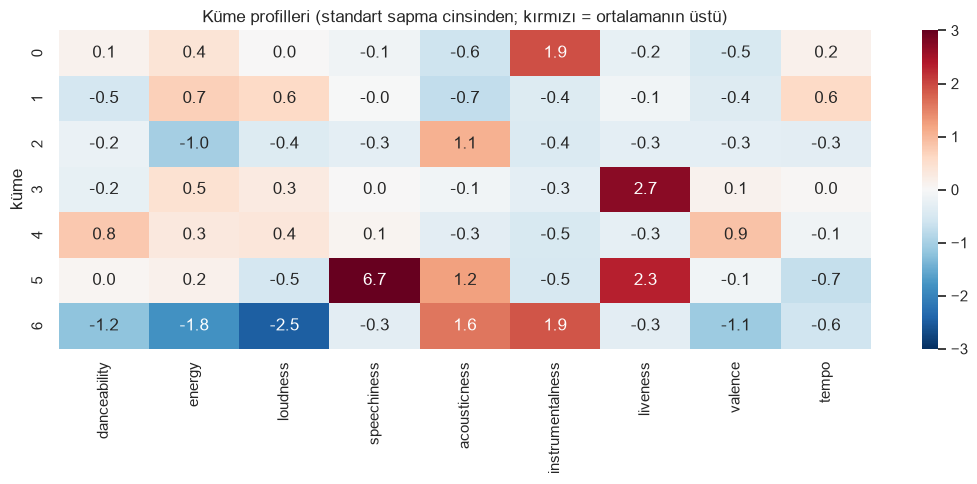

In [6]:
km = KMeans(n_clusters=7, n_init=10, random_state=RASTGELE).fit(X)
sarkilar["kume"] = km.labels_

# Kümelerin profili: her özelliğin ortalamaya göre kaç standart sapma yukarıda/aşağıda olduğu
profil = pd.DataFrame(km.cluster_centers_, columns=SES_OZELLIKLERI)

fig, eksen = plt.subplots(figsize=(11, 5))
sns.heatmap(profil, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-3, vmax=3, ax=eksen)
eksen.set_ylabel("küme")
eksen.set_title("Küme profilleri (standart sapma cinsinden; kırmızı = ortalamanın üstü)")
fig.tight_layout()
plt.show()

In [7]:
# Her kümede en sık görülen türler
for c in range(7):
    turler = sarkilar.loc[sarkilar["kume"] == c, "track_genre"].value_counts(normalize=True).head(5)
    print(f"Küme {c} ({(sarkilar['kume'] == c).sum():>6,} şarkı):",
          ", ".join(f"{t} %{p*100:.0f}" for t, p in turler.items()))

Küme 0 (10,088 şarkı): minimal-techno %8, detroit-techno %7, study %6, grindcore %5, chicago-house %5
Küme 1 (20,183 şarkı): heavy-metal %4, hardstyle %3, grunge %3, metalcore %3, death-metal %3
Küme 2 (18,092 şarkı): tango %4, honky-tonk %4, romance %4, cantopop %4, acoustic %3
Küme 3 ( 6,207 şarkı): pagode %7, sertanejo %6, samba %4, mpb %4, forro %3
Küme 4 (27,504 şarkı): dancehall %3, salsa %3, kids %3, forro %2, dance %2
Küme 5 ( 1,042 şarkı): comedy %77, show-tunes %3, children %2, kids %2, french %1
Küme 6 ( 6,462 şarkı): new-age %12, ambient %10, sleep %10, classical %10, disney %7


Kümelere bir isim vermek için iki şeye bakıyoruz: profil ısı haritasında hangi özelliklerin öne çıktığı ve en sık hangi türlerin geçtiği. Örnek şarkıları da **küme merkezine en yakın** olanlardan seçiyoruz, yani kümenin "en tipik" şarkılarından. Tanınabilir olsunlar diye popülerliği 40'ın üstündekilere bakıyoruz.

> Not: Küme numaraları (0–6) K-Means'in rastgele başlangıcına bağlı. `random_state` sabit olduğu için her çalıştırmada aynı çıkıyor. Ama verinin ya da kütüphane sürümünün değişmesi isimlerin yeniden kontrol edilmesini gerektirir.

In [8]:
uzaklik = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
sarkilar["merkeze_uzaklik"] = uzaklik

for c in range(7):
    tipik = (sarkilar[(sarkilar["kume"] == c) & (sarkilar["popularity"] >= 40)]
             .nsmallest(5, "merkeze_uzaklik"))
    print(f"Küme {c}:")
    for _, s in tipik.iterrows():
        print(f"   {s['track_name'][:45]:<45} — {s['artists'][:30]}  ({s['track_genre']})")

Küme 0:
   Safe                                          — Monkey Safari  (deep-house)
   Fingerprint                                   — Lane 8  (progressive-house)
   EASY PREY                                     — Moderat  (minimal-techno)
   Desire                                        — Bob Moses;ZHU  (electronic)
   Discrete                                      — Noisecream  (club)
Küme 1:
   Ghost                                         — Badflower  (grunge)
   Lost In The Wild                              — WALK THE MOON  (alt-rock)
   Blind Faith                                   — Chase & Status;Liam Bailey  (drum-and-bass)
   A Fênix                                       — Rosa de Saron  (brazil)
   Loser                                         — 3 Doors Down  (grunge)
Küme 2:
   Tudo Vai Passar                               — Gabriel Brito  (gospel)
   下一位前度 in Ab major                             — Terence Lam  (cantopop)
   Pal Pal Dil Ke Paas - Lofi                    —

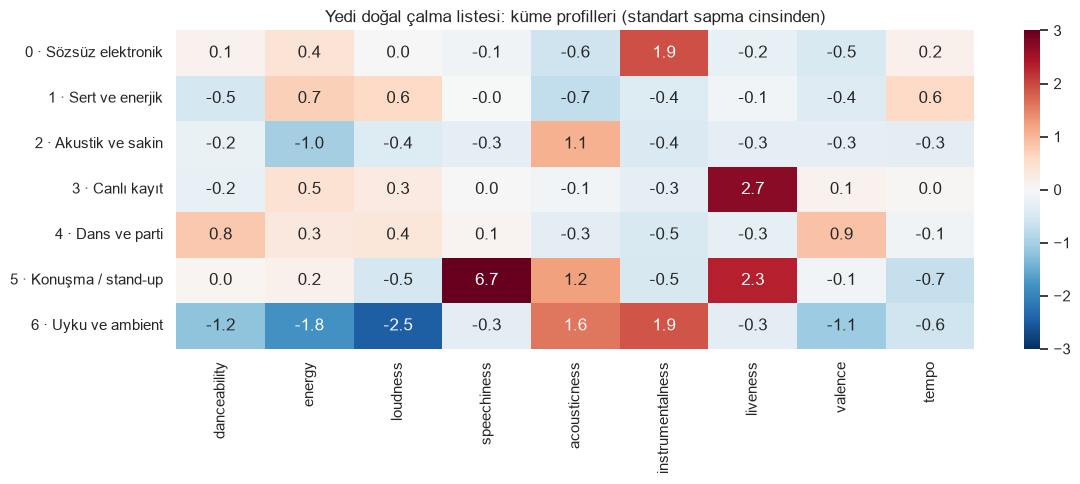

In [9]:
KUME_ADLARI = {
    0: "Sözsüz elektronik",
    1: "Sert ve enerjik",
    2: "Akustik ve sakin",
    3: "Canlı kayıt",
    4: "Dans ve parti",
    5: "Konuşma / stand-up",
    6: "Uyku ve ambient",
}
sarkilar["kume_adi"] = sarkilar["kume"].map(KUME_ADLARI)

profil.index = [f"{i} · {KUME_ADLARI[i]}" for i in profil.index]
fig, eksen = plt.subplots(figsize=(12, 5))
sns.heatmap(profil, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-3, vmax=3, ax=eksen)
eksen.set_title("Yedi doğal çalma listesi: küme profilleri (standart sapma cinsinden)")
fig.tight_layout()
fig.savefig(FIGURLER / "02_kume_profilleri.png", dpi=120)
plt.show()

| Küme | Ad | Belirleyici özellikler |
|---|---|---|
| 0 | Sözsüz elektronik | Yüksek `instrumentalness`, enerjik. Techno, house, IDM ve "study" listeleri |
| 1 | Sert ve enerjik | En yüksek `energy` ve `loudness`, düşük `valence`. Metal, hardstyle, grunge |
| 2 | Akustik ve sakin | Yüksek `acousticness`, düşük enerji. Tango, akustik, romantik |
| 3 | Canlı kayıt | Çok yüksek `liveness`. Brezilya türleri (pagode, sertanejo, samba) baskın |
| 4 | Dans ve parti | En yüksek `danceability` ve `valence`. Dancehall, salsa, Latin |
| 5 | Konuşma / stand-up | Aşırı yüksek `speechiness`. Şarkıların çoğu comedy türünde |
| 6 | Uyku ve ambient | En düşük enerji ve ses, yüksek `instrumentalness`. New-age, ambient, sleep, klasik |

Algoritmaya tür bilgisini hiç vermedik. Buna rağmen kümeler gerçek hayattaki çalma listelerine benziyor. 3 numaralı kümenin ortaya çıkması ayrıca ilginç: Brezilya müziği bu veri setinde çoğunlukla canlı kayıtlarla temsil ediliyor.

## 5. Görselleştirme: 9 boyutu 2 boyuta indirmek

### 5.1 PCA

PCA, veriyi en çok çeşitliliğin olduğu yönlere döndürür. İlk iki bileşen verideki çeşitliliğin ne kadarını açıklıyor?

In [10]:
pca = PCA(random_state=RASTGELE).fit(X)
print("Açıklanan varyans oranları:", pca.explained_variance_ratio_.round(3))
print(f"İlk iki bileşen toplamı: %{pca.explained_variance_ratio_[:2].sum()*100:.0f}")

bilesenler = pd.DataFrame(pca.components_[:2], columns=SES_OZELLIKLERI, index=["PC1", "PC2"])
bilesenler.round(2)

Açıklanan varyans oranları: [0.319 0.16  0.139 0.101 0.097 0.082 0.051 0.036 0.015]
İlk iki bileşen toplamı: %48


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
PC1,0.25,0.51,0.52,0.10,-0.44,-0.28,0.09,0.30,0.19
PC2,0.57,-0.28,-0.08,0.04,0.31,-0.32,-0.21,0.53,-0.28


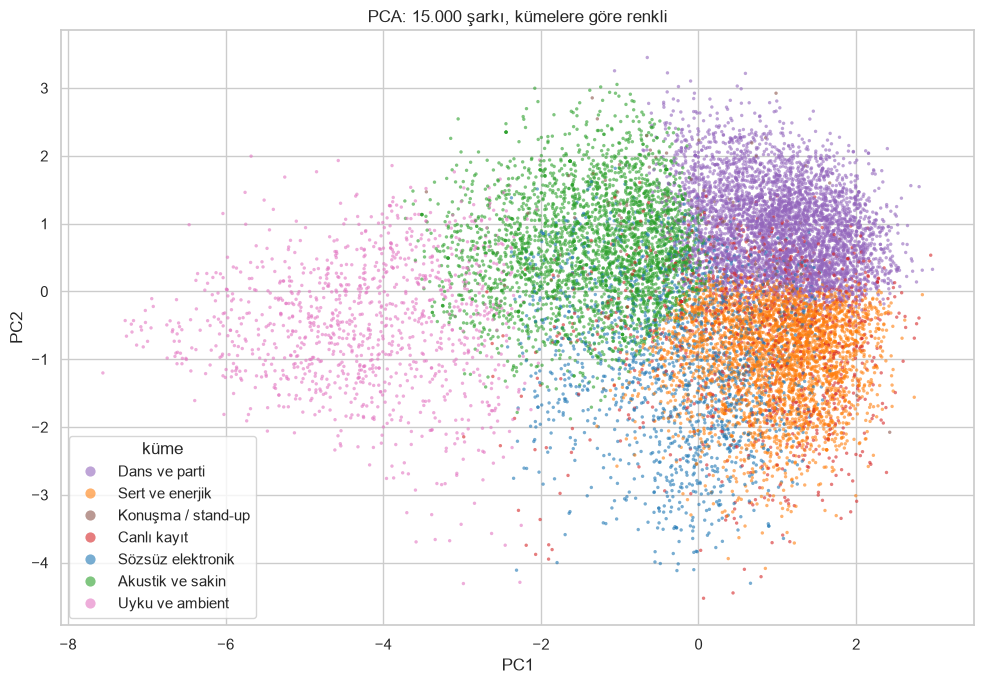

In [11]:
cizim = rng.choice(len(X), 15_000, replace=False)
X_pca = pca.transform(X[cizim])[:, :2]
palet = dict(zip(KUME_ADLARI.values(), sns.color_palette("tab10", 7)))

fig, eksen = plt.subplots(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=sarkilar["kume_adi"].iloc[cizim].values,
                palette=palet, s=6, alpha=0.6, linewidth=0, ax=eksen)
eksen.set_xlabel("PC1")
eksen.set_ylabel("PC2")
eksen.set_title("PCA: 15.000 şarkı, kümelere göre renkli")
eksen.legend(markerscale=3, title="küme")
fig.tight_layout()
plt.show()

### 5.2 t-SNE

PCA doğrusal bir yöntem, kümeleri iki boyutta ancak kısmen ayırabiliyor. **t-SNE** ise birbirine yakın şarkıları haritada da yakın tutmaya çalışan doğrusal olmayan bir yöntem. Hesabı ağır olduğu için 8.000 şarkılık bir örneklem kullanıyoruz.

> t-SNE haritasında kümeler arası **mesafeler** ve kümelerin **boyutları** yorumlanmaz. Sadece "hangi şarkılar birbirine komşu" bilgisi anlamlıdır.

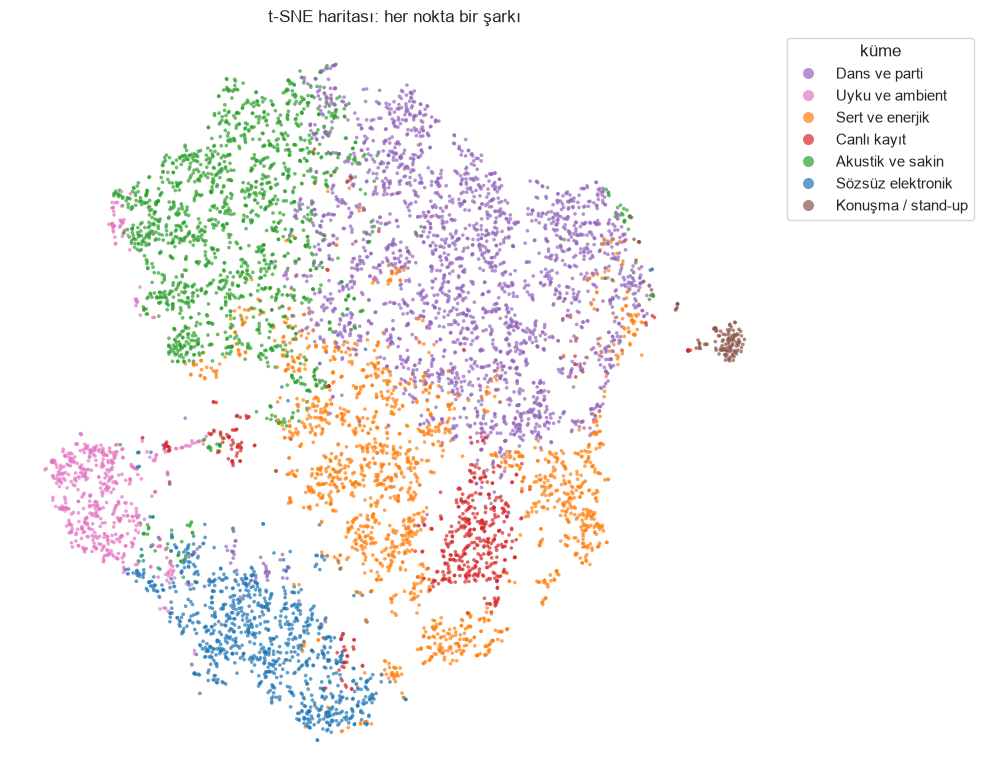

In [12]:
tsne_idx = rng.choice(len(X), 8_000, replace=False)
X_tsne = TSNE(n_components=2, perplexity=40, random_state=RASTGELE, init="pca").fit_transform(X[tsne_idx])
tsne_df = sarkilar.iloc[tsne_idx].assign(x=X_tsne[:, 0], y=X_tsne[:, 1])

fig, eksen = plt.subplots(figsize=(10, 8))
sns.scatterplot(data=tsne_df, x="x", y="y", hue="kume_adi", palette=palet,
                s=7, alpha=0.7, linewidth=0, ax=eksen)
eksen.set_axis_off()
eksen.set_title("t-SNE haritası: her nokta bir şarkı")
eksen.legend(markerscale=3, title="küme", loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(FIGURLER / "02_tsne_kumeler.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Türler ses gruplarıyla örtüşüyor mu?

Her tür için şu soruyu soruyoruz: Bu türün şarkılarının **en büyük kısmı** tek bir kümeye mi düşüyor, yoksa kümelere dağılıyor mu? Bu oranı türün **"ses tutarlılığı"** olarak adlandırıyoruz. Bu bölümde tür düzeyindeki veriyi kullanıyoruz, çünkü bir şarkı birden fazla türe ait olabilir.

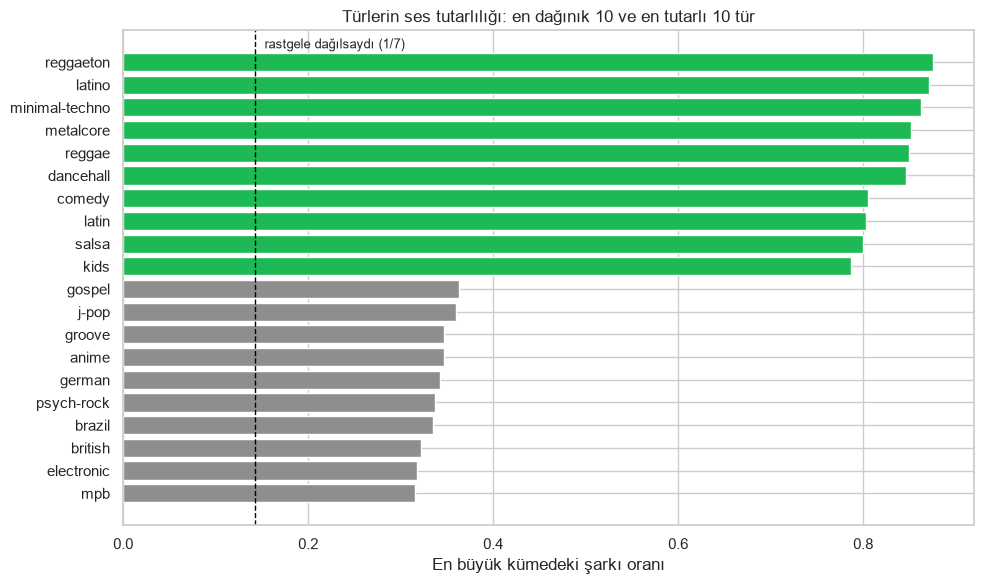

Medyan tutarlılık: %53


In [13]:
df["kume"] = km.predict(olcekleyici.transform(df[SES_OZELLIKLERI]))
tutarlilik = (df.groupby("track_genre")["kume"]
              .agg(lambda k: k.value_counts(normalize=True).iloc[0])
              .sort_values())

fig, eksen = plt.subplots(figsize=(10, 6))
secim = pd.concat([tutarlilik.head(10), tutarlilik.tail(10)])
renkler = ["#8E8E8E"] * 10 + ["#1DB954"] * 10
eksen.barh(secim.index, secim.values, color=renkler)
eksen.axvline(1 / 7, ls="--", color="black", lw=1)
eksen.text(1 / 7 + 0.01, len(secim) - 0.4, "rastgele dağılsaydı (1/7)", fontsize=9)
eksen.set_xlabel("En büyük kümedeki şarkı oranı")
eksen.set_title("Türlerin ses tutarlılığı: en dağınık 10 ve en tutarlı 10 tür")
fig.tight_layout()
fig.savefig(FIGURLER / "02_tur_tutarliligi.png", dpi=120)
plt.show()

print(f"Medyan tutarlılık: %{tutarlilik.median()*100:.0f}")

**Yorum:**
- **Ses olarak en tutarlı türler** reggaeton, latino ve minimal-techno. Bunlar belirli bir **ritim ve üretim kalıbıyla** tanımlanan türler.
- **En dağınık türler** ise mpb, british, german, brazil gibi **coğrafya ya da kültürle** tanımlanan şemsiye etiketler. "British" bir ses değil, bir köken. İçinde hem punk hem balad var.
- Sonuç: Türler kısmen ses gruplarıyla örtüşüyor. Ritim temelli türler ayrışıyor, coğrafi ve kültürel etiketler ayrışmıyor. Bu, ileride yapacağımız **tür tahmininin** neden bazı türlerde başarılı, bazılarında başarısız olacağını da önceden gösteriyor.

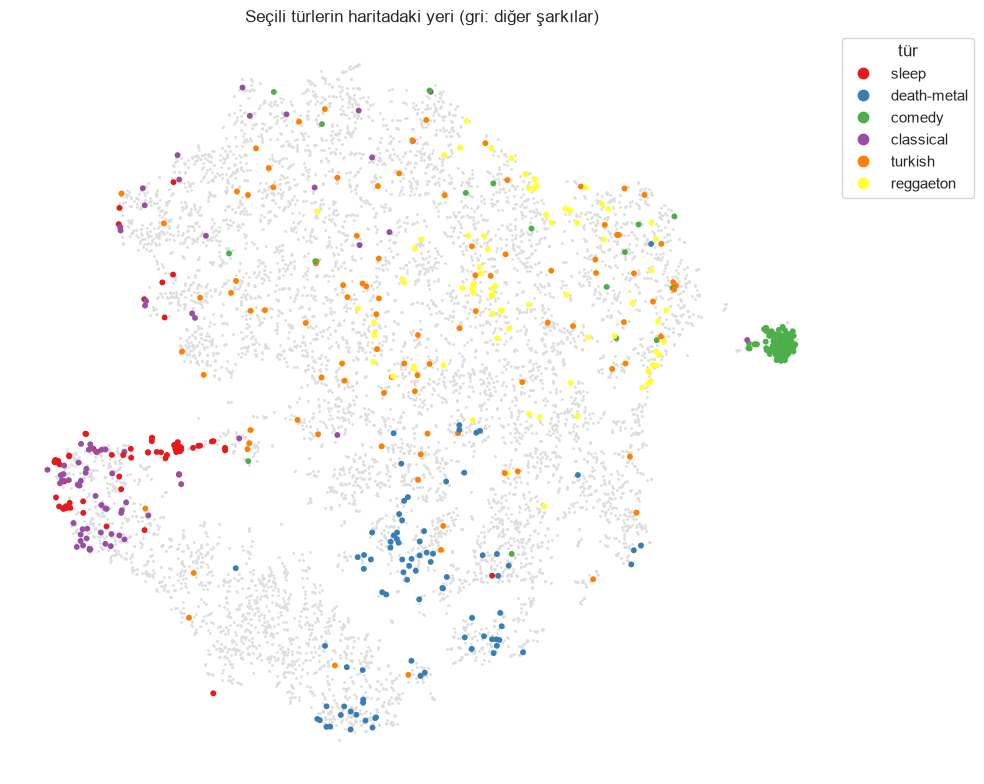

track_genre
comedy         111
turkish         96
reggaeton       90
death-metal     85
sleep           78
classical       75
Name: count, dtype: int64

In [14]:
# Seçilen birkaç türün t-SNE haritasındaki yeri
secili = ["classical", "death-metal", "reggaeton", "sleep", "comedy", "turkish"]
tur_tsne = df[df["track_genre"].isin(secili)].drop_duplicates("track_id")
tsne_tur = tsne_df[["track_id", "x", "y"]].merge(tur_tsne[["track_id", "track_genre"]], on="track_id")

fig, eksen = plt.subplots(figsize=(10, 8))
eksen.scatter(tsne_df["x"], tsne_df["y"], s=4, color="#DDDDDD", linewidth=0)
sns.scatterplot(data=tsne_tur, x="x", y="y", hue="track_genre", palette="Set1",
                s=18, linewidth=0, ax=eksen)
eksen.set_axis_off()
eksen.set_title("Seçili türlerin haritadaki yeri (gri: diğer şarkılar)")
eksen.legend(markerscale=2, title="tür", loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(FIGURLER / "02_tsne_turler.png", dpi=120, bbox_inches="tight")
plt.show()

tsne_tur["track_genre"].value_counts()

## 7. Türk müziği hangi çalma listelerine düşüyor?

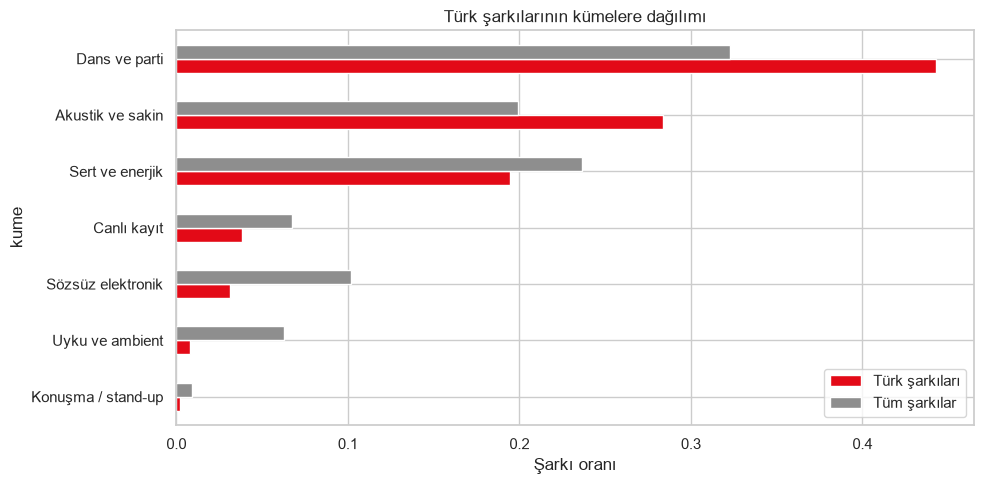

,Türk şarkıları,Tüm şarkılar
kume,,
Konuşma / stand-up,0.2,0.9
Uyku ve ambient,0.8,6.3
Sözsüz elektronik,3.1,10.2
Canlı kayıt,3.8,6.7
Sert ve enerjik,19.4,23.7
Akustik ve sakin,28.4,19.9
Dans ve parti,44.3,32.3


In [15]:
turk_dagilim = pd.DataFrame({
    "Türk şarkıları": df.loc[df["track_genre"] == "turkish", "kume"].value_counts(normalize=True),
    "Tüm şarkılar": df["kume"].value_counts(normalize=True),
}).fillna(0)
turk_dagilim.index = turk_dagilim.index.map(KUME_ADLARI)
turk_dagilim = turk_dagilim.sort_values("Türk şarkıları")

fig, eksen = plt.subplots(figsize=(10, 5))
turk_dagilim.plot.barh(ax=eksen, color=["#E30A17", "#8E8E8E"])
eksen.set_xlabel("Şarkı oranı")
eksen.set_title("Türk şarkılarının kümelere dağılımı")
fig.tight_layout()
fig.savefig(FIGURLER / "02_turk_kumeler.png", dpi=120)
plt.show()

(turk_dagilim * 100).round(1)

In [16]:
sira = tutarlilik.rank(ascending=False).astype(int)
print(f"Türk müziğinin ses tutarlılığı: %{tutarlilik['turkish']*100:.0f} "
      f"(114 tür içinde {sira['turkish']}. sırada, medyan %{tutarlilik.median()*100:.0f})")

Türk müziğinin ses tutarlılığı: %44 (114 tür içinde 81. sırada, medyan %53)


**Yorum:** Türk şarkıları en çok iki uçta toplanıyor: **dans ve parti** (%44, genelde %32) ile **akustik ve sakin** (%28, genelde %20). Bu ikisinin toplamı %73. Sözsüz elektronik, uyku/ambient ve canlı kayıt kümelerinde ise Türk şarkısı neredeyse yok.

Türk müziğinin ses tutarlılığı %44 ile medyanın altında. t-SNE haritasında da Türk şarkıları tek bir bölgede toplanmıyor, haritanın her yerine dağılıyor. Yani "turkish" etiketi, "british" ve "german" gibi bir **ses tarzını değil bir kökeni** anlatıyor. İçinde pop, rap, arabesk ve rock birlikte var.

## 8. Özet

- **Müzik keskin gruplara ayrılmıyor.** Silhouette skorları 0.16–0.25 aralığında kalıyor. Şarkılar sürekli bir yelpazeye yayılıyor. Bu yüzden kümeleri katı kategoriler olarak değil, "bölgeler" olarak okumak gerekiyor.
- **Buna rağmen 7 anlamlı "çalma listesi" ortaya çıkıyor:** sözsüz elektronik, sert ve enerjik, akustik ve sakin, canlı kayıt, dans ve parti, konuşma ve uyku/ambient. Algoritmaya tür bilgisi hiç verilmedi.
- **Müziğin iki ana ekseni** (PCA, varyansın %48'i): 1) enerji ve ses yüksekliği ile akustiklik arasındaki eksen, 2) dans edilebilirlik ve mutluluk ekseni.
- **Türlerin yarısı ses olarak tutarlı, yarısı değil** (medyan %53). Ritim ve üretim kalıbıyla tanımlanan türler (reggaeton, latino, minimal-techno) %85 ve üzeri oranda tek kümede toplanıyor. Coğrafi etiketler (british, german, brazil, mpb) ise %32–34'te kalıyor.
- **Türk müziği** iki kutupta yoğunlaşıyor: dans/parti ve akustik/sakin. Ses olarak dağınık bir tür, yani bir tarzdan çok bir kökeni temsil ediyor.

**Sonraki adım:** `03_hit_tahmini.ipynb` — ses özellikleri bir şarkının popülerliğini tahmin edebilir mi?